# Experiments from October 12 on
See tex/main.pdf, Sections 2.4 to 2.6. 

In [7]:
%run base.ipynb

mare


## Union bound

We plot
\begin{equation}
\mathbb E_D[R(\hat h_D) - \hat R_D(\hat h_D)] \le \sqrt{\frac{d}{n}}
\end{equation}
obtained by Theorem 2.5 in Section 2 and $\log \vert\mathcal H_d\vert \le d$.

[checkpoint] bound: "unionbound" -> union_bound, params: []


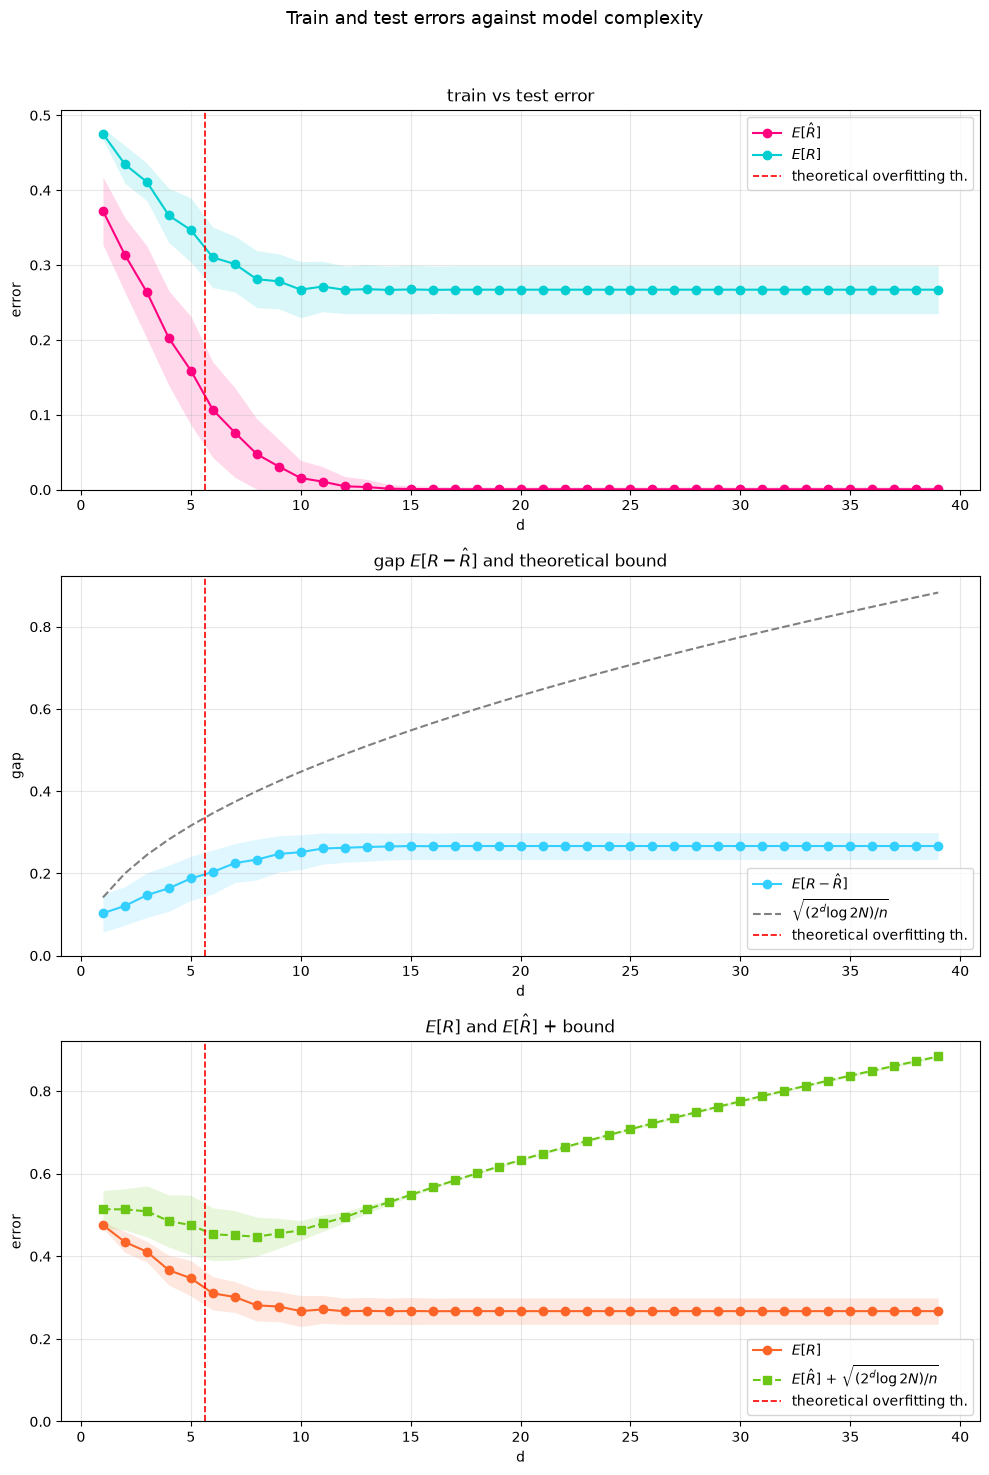

In [5]:
# MODEL
mymodel = DecisionTreeClassifier

# PARAMETERS
supp_size = 10_000
data_size_test = 200_000
data_size_tr = 50
noise_std = 3
num_iter = 100
num_crossings = 10

from functools import partial
mysine = partial(sine, m = num_crossings)

# build test set
x_test = sample_x(data_size_test, supp_size)
y_test = sample_y(x = x_test, f = mysine, sigma = noise_std)

# build models and do plots
hat_Rs, Rs, gaps, std_hat_Rs, std_Rs, std_gaps, predictions, x, y, x_grid = main_loop(
    x_test, y_test, n = data_size_tr, sigma = noise_std, T = num_iter, model = mymodel,
    f = mysine,
    N = supp_size)
plots(hat_Rs, Rs, gaps, std_hat_Rs=std_hat_Rs, std_Rs=std_Rs, std_gaps=std_gaps, 
      n = data_size_tr, sigma = noise_std, T= num_iter, model = mymodel, 
      bound_name = "unionbound", bound_params = {}
      )

## Rademacher + Massart

We plot

\begin{equation}
\mathbb E_D[R(\hat h_D) - \hat R_D(\hat h_D)] \le \min\left\{\sqrt{\frac{\log \vert \mathcal H \vert}{n}}, 1\right\}
\end{equation}

obtained from $N(D) \le \min\{\vert \mathcal H\vert, 2^n\}$, equation (58). 

[checkpoint] bound: "rademmassart" -> radem_massart_bound, params: []


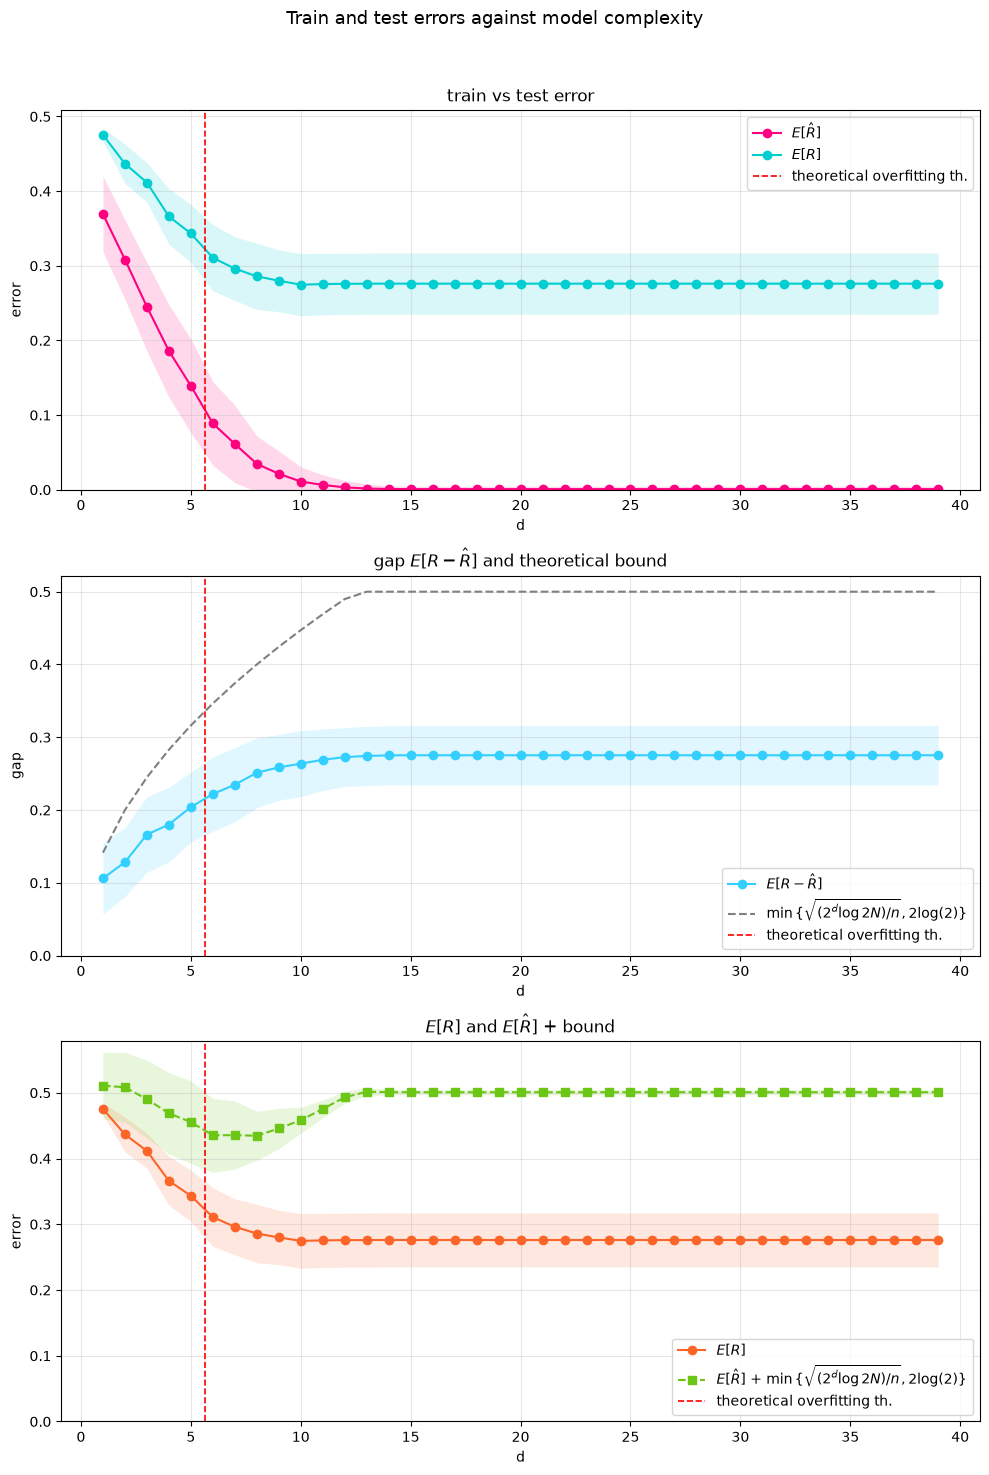

In [8]:
# build models and do plots
hat_Rs, Rs, gaps, std_hat_Rs, std_Rs, std_gaps, predictions, x, y, x_grid = main_loop(
    x_test, y_test, n = data_size_tr, sigma = noise_std, T = num_iter, model = mymodel,
    f = mysine,
    N = supp_size)
plots(hat_Rs, Rs, gaps, std_hat_Rs=std_hat_Rs, std_Rs=std_Rs, std_gaps=std_gaps, 
      n = data_size_tr, sigma = noise_std, T= num_iter, model = mymodel, 
      bound_name = "rademmassart", bound_params = {}
      )

### vedi che non si sposta con il rumore!

[checkpoint] bound: "rademmassart" -> radem_massart_bound, params: []
[checkpoint] bound: "rademmassart" -> radem_massart_bound, params: []
[checkpoint] bound: "rademmassart" -> radem_massart_bound, params: []


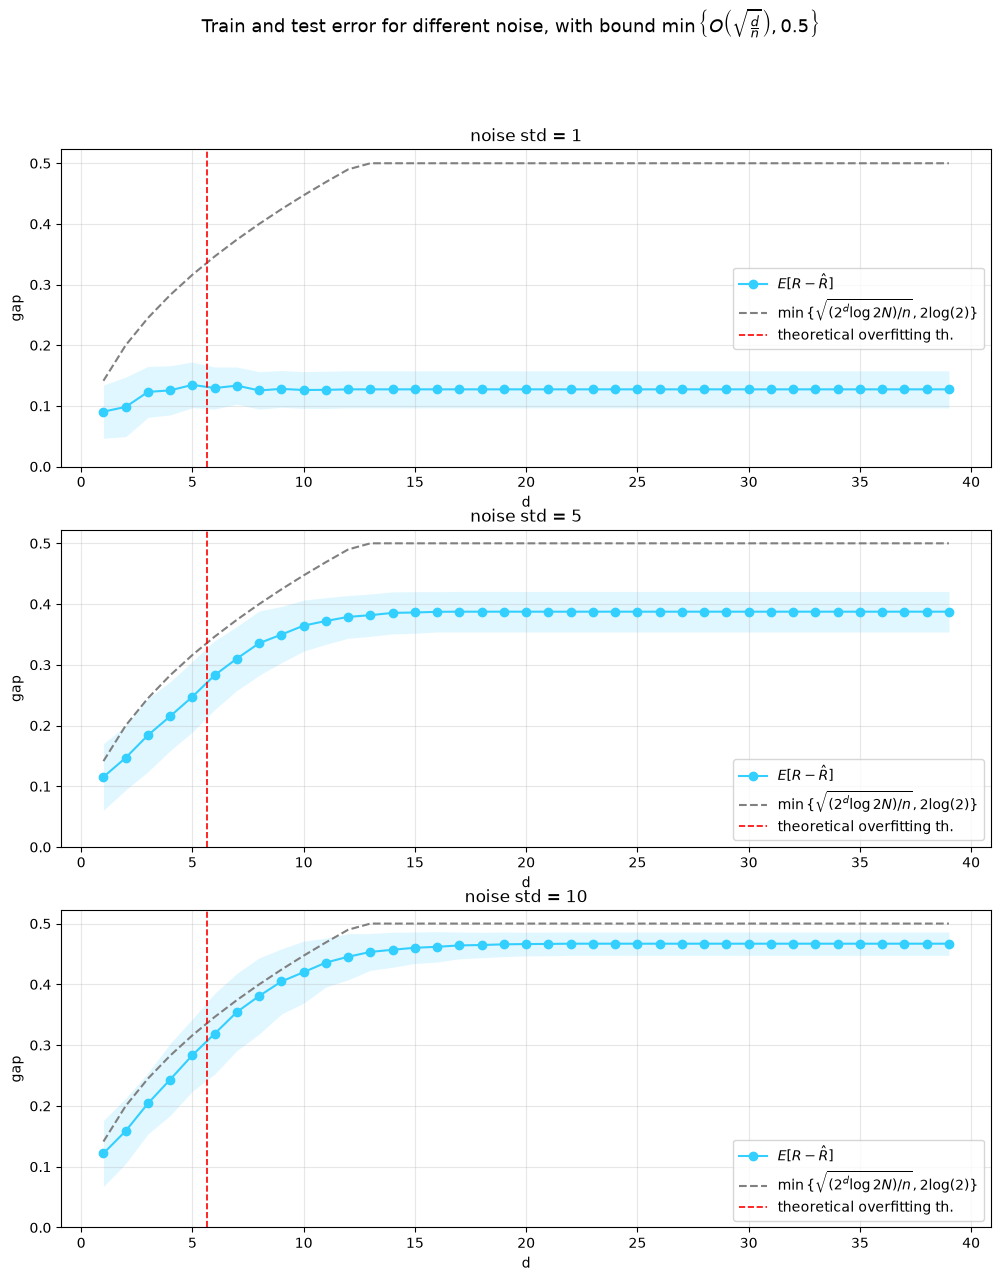

In [9]:
import matplotlib.pyplot as plt
fig, axs = plt.subplots(3, 1, figsize=(12, 14))
fig.suptitle(r'Train and test error for different noise, with bound $\min\left\{O\left(\sqrt{\frac{d}{n}}\right), 0.5\right\}$', fontsize=13)

# noises
my_noise_stds = [1, 5, 10]

for ax, my_noise_std in zip(axs.flat, my_noise_stds):
    # build test set
    x_test = sample_x(data_size_test, supp_size)
    y_test = sample_y(x=x_test, f=mysine, sigma=my_noise_std)

    # build models and do plots 
    hat_Rs, Rs, gaps, std_hat_Rs, std_Rs, std_gaps, predictions, x, y, x_grid = main_loop(
        x_test, y_test, n=data_size_tr, sigma=my_noise_std, T=num_iter, model=mymodel, f=mysine, N=supp_size)
    plots(hat_Rs, Rs, gaps, std_hat_Rs=std_hat_Rs, std_Rs=std_Rs, std_gaps=std_gaps, 
          n=data_size_tr, sigma=my_noise_std, T=num_iter, model=mymodel, 
          one=False, three=False, axes=[ax],
          bound_name = "rademmassart", bound_params = {})
    ax.set_title(f'noise std = {my_noise_std}')

# Runtime ~2 min for 3 noise stds

## Bounds with the best risk

We plot 
\begin{equation}

\end{equation}